# Same crop at 32, 48 and 64 pixels

This is a visual explanation of the resize-height decision. It does not run OCR or training. The crop is kept at the same aspect ratio, so increasing the height also gives the writing more horizontal pixels and therefore more useful CTC positions.

The slot count below is an estimate of useful writing-width slots (`resized width / 8`). The real tensor may contain right-side padding; padding is not extra handwriting information.

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

roots = [Path.cwd(), *Path.cwd().parents]
A = next(p for p in roots if (p / 'JH_datasetNov5Sentence').is_dir())
crop_path = A / 'JH_datasetNov5Sentence/train/JH3.8_zoomout.jpg'
image = Image.open(crop_path).convert('RGB')
print('Crop:', crop_path.relative_to(A))
print('Original pixels:', image.size)

Crop: JH_datasetNov5Sentence/train/JH3.8_zoomout.jpg
Original pixels: (1033, 142)


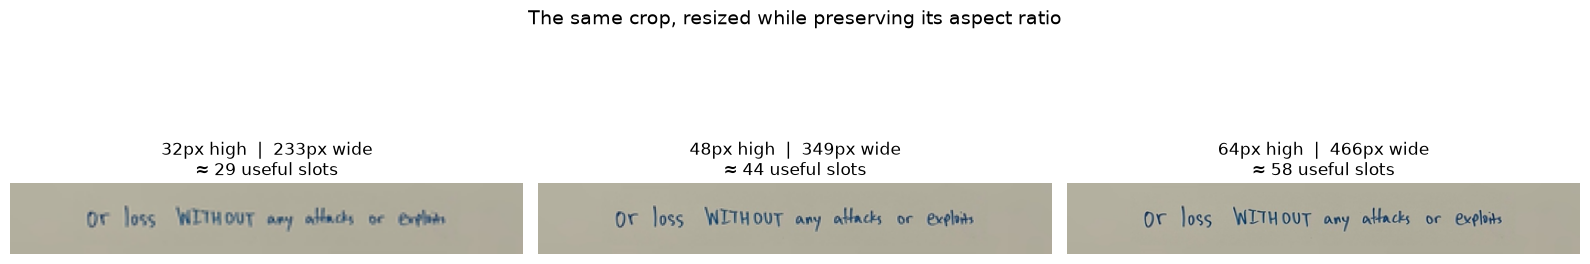

In [ ]:
heights = [32, 48, 64]
versions = []
for h in heights:
    w = round(image.width * h / image.height)
    resized = image.resize((w, h), Image.Resampling.LANCZOS)
    slots = w / 8
    versions.append((h, w, slots, resized))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (h, w, slots, resized) in zip(axes, versions):
    ax.imshow(resized)
    ax.set_title(f'{h}px high  |  {w}px wide\n≈ {slots:.0f} useful slots')
    ax.axis('off')
fig.suptitle('The same crop, resized while preserving its aspect ratio', fontsize=14)
fig.tight_layout()
plt.show()

## How to read the picture

At 32 pixels, the line becomes shorter and the letters are packed into fewer useful horizontal positions. At 64 pixels, the same writing is larger and spreads across more positions.

This is why the earlier audit found fewer lines with insufficient sequence space at 64 pixels. It does **not** mean that the model literally cuts the sentence into one character per column. Each CTC position is a feature summary that may contribute to a character alignment.

In [ ]:
rows = ['| Height | Resized width | Approx. useful slots |', '|---:|---:|---:|']
rows += [f'| {h} px | {w} px | {slots:.1f} |' for h, w, slots, _ in versions]
display(Markdown('\n'.join(rows)))

| Height | Resized width | Approx. useful slots |
|---:|---:|---:|
| 32 px | 233 px | 29.1 |
| 48 px | 349 px | 43.6 |
| 64 px | 466 px | 58.2 |